# 12 · Learning to control: imitation learning vs reinforcement learning
**Level 5 · Learning control policies** &nbsp;|&nbsp; Course link: *Module 4 – reinforcement learning for energy
management; imitation learning and the accumulation of errors; safe actions*

MPC (notebook 11) solves an optimisation problem **every hour**. A *learned policy* $\pi(\text{state})\to\text{action}$
replaces that optimisation by one cheap function evaluation. Two ways to get it:

| | **Imitation learning** | **Reinforcement learning** |
|---|---|---|
| learns from | an expert's decisions (here: the MPC) | rewards, by trial and error |
| machine-learning type | supervised classification | sequential decision making (MDP) |
| strength | fast, data-efficient | can exceed its teacher, needs no expert |
| weakness | **compounding errors** outside the expert's states | slow, unsafe exploration |

**Task:** operate a 10 kWh / 5 kW home battery with 8 kWp PV and a dynamic tariff (same home as notebook 11, no EV).
Every hour the policy picks one of 5 **operating modes**, the way home batteries are actually commanded: *idle*,
*self-consume* (store PV surplus, cover deficits), *store surplus only* (save energy for later), *self-consume + charge
2.5 kW from the grid*, *discharge at full power*.
Train on March–August 2019, test on September 2019.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import linprog
import gymnasium as gym
import torch, torch.nn as nn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from energy_ai import home_profiles, set_seed, style
style(); set_seed(0)

home = home_profiles()
LOAD, PV, BUY = home.load_kw.values, home.pv_kw.values, home.buy_eur_kwh.values
NET = LOAD - PV
E, PB, ETA, EMIN, SELL, WEAR, H = 10.0, 5.0, 0.95, 1.0, 0.08, 0.01, 24
ACTIONS = ["idle", "self-consume", "store surplus only", "self-consume + grid charge", "discharge at full power"]
NA = len(ACTIONS)

def action_power(a, t):
    """Battery power [kW, + = charge] requested by operating mode a in hour t (net = load - PV)."""
    n = NET[t]
    return (0.0, -n, max(-n, 0.0), max(-n, 0.0) + 2.5, -PB)[a]

def nearest_action(t, p, soc):
    """Mode whose *physically applied* power (after the shield, defined below) is closest to p; ties -> self-consume."""
    d = np.array([abs(shield(action_power(a, t), soc) - p) for a in range(NA)])
    best = np.flatnonzero(d <= d.min() + 1e-6)
    return 1 if 1 in best else int(best[0])
idx = lambda day: home.index.get_loc(pd.Timestamp(day))
TRAIN = (idx("2019-03-01"), idx("2019-09-01"))
TEST = (idx("2019-09-01"), idx("2019-10-01"))
print(f"training hours: {TRAIN[1] - TRAIN[0]} | test hours: {TEST[1] - TEST[0]}")

training hours: 4416 | test hours: 720


## 1. The environment (Gymnasium API) with a safety shield
State → features the policy sees: state of charge, time of day, current net load, outlook of net load and prices.
**Safety:** an action that would over-charge or over-discharge the battery is **clipped by a shield** before it reaches
the hardware. Learning agents, especially while exploring, propose such actions often; the shield guarantees that the
physical limits are never violated and counts the interventions.

In [2]:
def features(t, soc):
    h = t % 24
    nxt = slice(t + 1, t + 25)
    p24 = BUY[t:t + 24]
    return np.array([soc / E, np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), NET[t],
                     NET[t + 1:t + 7].mean(), NET[nxt].mean(), PV[nxt].sum() / E,
                     100 * (BUY[t] - p24.mean()), (p24 < BUY[t]).mean()], dtype=np.float32)

def shield(power, soc):
    """Clip a requested battery power to what the battery can physically do in one hour."""
    return float(np.clip(power, -min(PB, (soc - EMIN) * ETA), min(PB, (E - soc) / ETA)))

def step_cost(t, power):
    grid = NET[t] + power
    return BUY[t] * max(grid, 0) - SELL * max(-grid, 0) + WEAR * abs(power)

class HomeBatteryEnv(gym.Env):
    def __init__(self, start, stop, episode_hours=7 * 24, random_start=True, seed=0):
        self.start, self.stop, self.len, self.random_start = start, stop, episode_hours, random_start
        self.rng = np.random.default_rng(seed)
        self.action_space = gym.spaces.Discrete(NA)
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, shape=(9,), dtype=np.float32)
    def reset(self, seed=None, options=None):
        self.t = (self.start + 24 * self.rng.integers(0, (self.stop - self.start - self.len) // 24)) if self.random_start else self.start
        self.t_end = min(self.t + self.len, self.stop)
        self.soc = 0.5 * E
        return features(self.t, self.soc), {}
    def step(self, action):
        req = action_power(action, self.t); p = shield(req, self.soc)
        cost = step_cost(self.t, p)
        self.soc += ETA * max(p, 0) + min(p, 0) / ETA
        self.t += 1
        done = self.t >= self.t_end
        return features(self.t, self.soc), -cost, done, False, {"shielded": abs(p - req) > 1e-9, "cost": cost}

## 2. The expert: MPC with a perfect 24-hour forecast
The same LP as notebook 11 (battery only). It is our *teacher* and the benchmark.

In [3]:
def mpc_action(t, soc):
    I, Z = sp.eye(H), sp.csr_matrix((H, H))
    A_eq = sp.vstack([sp.hstack([-I, I, I, -I, Z]),                                   # imp - exp - ch + dis = net
                      sp.hstack([-ETA * I, I / ETA, Z, Z, sp.eye(H) - sp.eye(H, k=-1)])])  # soc dynamics
    b_eq = np.r_[NET[t:t + H], soc, np.zeros(H - 1)]
    bt = BUY[t:t + H]
    c = np.r_[np.full(H, WEAR), np.full(H, WEAR), bt, np.full(H, -SELL), np.zeros(H)]
    c[-1] -= 0.5 * (bt.mean() + SELL)                                                   # value of energy left at the end
    c[4 * H:] -= 0.002                                                                  # tie-breaker: store early
    bounds = [(0, PB)] * 2 * H + [(0, None)] * 2 * H + [(EMIN, E)] * H
    x = linprog(c, A_eq=A_eq.tocsr(), b_eq=b_eq, bounds=bounds, method="highs").x
    return x[0] - x[H]                                                                  # charge - discharge, first hour

def rollout(policy, start, stop, soc0=0.5 * E, record=False):
    """Run a policy (function (t, soc) -> requested power [kW]) through [start, stop); returns bill and trajectory."""
    soc, bill, n_shield, traj = soc0, 0.0, 0, []
    for t in range(start, stop):
        req = policy(t, soc); p = shield(req, soc)
        n_shield += abs(p - req) > 1e-6
        bill += step_cost(t, p) - WEAR * abs(p)                                          # wear is not on the bill
        if record: traj.append((t, soc, p))
        soc += ETA * max(p, 0) + min(p, 0) / ETA
    return bill, n_shield, pd.DataFrame(traj, columns=["t", "soc", "power"]).set_index("t") if record else None

t0 = time.perf_counter()
expert_cont = rollout(mpc_action, *TEST, record=True)
expert_ms = 1000 * (time.perf_counter() - t0) / (TEST[1] - TEST[0])
expert_disc = rollout(lambda t, s: action_power(nearest_action(t, mpc_action(t, s), s), t), *TEST, record=True)
no_batt = rollout(lambda t, s: 0.0, *TEST)
rule = rollout(lambda t, s: -NET[t], *TEST, record=True)                                 # store surplus, cover deficit
results = {"no battery": no_batt, "rule-based (self-consumption)": rule,
           "expert MPC (continuous power)": expert_cont, "expert MPC mapped to the 5 modes": expert_disc}
print(f"expert MPC needs {expert_ms:.1f} ms per decision")
pd.DataFrame({k: {"September bill [€]": v[0]} for k, v in results.items()}).T.round(2)

expert MPC needs 6.7 ms per decision


,September bill [€]
no battery,24.48
rule-based (self-consumption),0.31
expert MPC (continuous power),0.17
expert MPC mapped to the 5 modes,0.19


## 3. Imitation learning: behaviour cloning
Record the expert's states and (rounded) actions on the training months, then fit a classifier
*features → action*. This is ordinary supervised learning.

In [4]:
def expert_dataset(start, stop):
    X, y, soc = [], [], 0.5 * E
    for t in range(start, stop):
        a = nearest_action(t, mpc_action(t, soc), soc)
        X.append(features(t, soc)); y.append(a)
        p = shield(action_power(a, t), soc); soc += ETA * max(p, 0) + min(p, 0) / ETA
    return np.array(X), np.array(y)

t0 = time.perf_counter()
X_exp, y_exp = expert_dataset(*TRAIN)
print(f"{len(X_exp)} expert decisions recorded in {time.perf_counter() - t0:.0f} s | action counts:",
      dict(zip(ACTIONS, np.bincount(y_exp, minlength=NA))))

def fit_policy(X, y):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=600, early_stopping=True,
                                                          random_state=0)).fit(X, y)

def as_policy(clf):
    return lambda t, soc: action_power(clf.predict(features(t, soc)[None, :])[0], t)

bc = fit_policy(X_exp, y_exp)
results["behaviour cloning"] = rollout(as_policy(bc), *TEST, record=True)

4416 expert decisions recorded in 31 s | action counts: {'idle': np.int64(328), 'self-consume': np.int64(4084), 'store surplus only': np.int64(0), 'self-consume + grid charge': np.int64(4), 'discharge at full power': np.int64(0)}


### The compounding-error problem
Supervised learning assumes test data come from the training distribution. In closed loop they do not: each mistake
moves the battery to a state of charge the expert would not have been in, where the clone has less training data,
may err again and drift further. Errors can **accumulate over time** instead of averaging out. We measure this by
comparing the clone's agreement with the expert on the *expert's* states and on the states it reaches *itself*.

behaviour cloning agrees with the expert on 91% of the EXPERT's test states and on 91% of the states it visits ITSELF


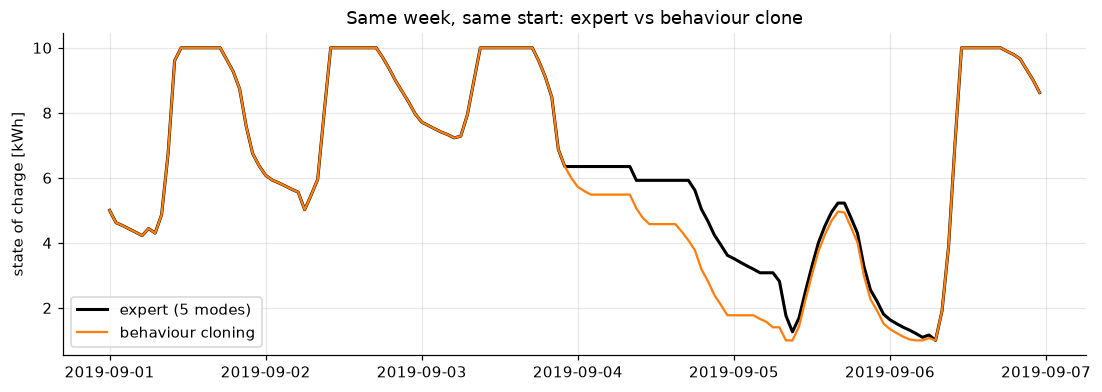

In [5]:
def agreement_on_own_states(clf, start, stop):
    """Run the learner, then ask the expert what it would have done in every state the learner visited."""
    _, _, traj = rollout(as_policy(clf), start, stop, record=True)
    own = clf.predict(np.array([features(t, s) for t, s in traj.soc.items()]))
    expert = [nearest_action(t, mpc_action(t, s), s) for t, s in traj.soc.items()]
    return np.mean(own == np.array(expert)), traj

X_te_exp, y_te_exp = expert_dataset(*TEST)
acc_expert_states = (bc.predict(X_te_exp) == y_te_exp).mean()
acc_own_states, bc_traj = agreement_on_own_states(bc, *TEST)
print(f"behaviour cloning agrees with the expert on {acc_expert_states:.0%} of the EXPERT's test states "
      f"and on {acc_own_states:.0%} of the states it visits ITSELF")

days = slice(TEST[0], TEST[0] + 6 * 24)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(home.index[days], expert_disc[2].soc.loc[days.start:days.stop - 1].values, "k", lw=2, label="expert (5 modes)")
ax.plot(home.index[days], bc_traj.soc.loc[days.start:days.stop - 1].values, color="tab:orange", label="behaviour cloning")
ax.set(ylabel="state of charge [kWh]", title="Same week, same start: expert vs behaviour clone"); ax.legend(); plt.show()

### DAgger: let the expert correct the learner's own mistakes
*Dataset Aggregation* (Ross et al., 2011): run the **learner**, ask the expert what it *should* have done in each state
the learner visited, add these labels to the dataset, retrain. The training data then covers the states the learner
actually reaches.

In [6]:
X_agg, y_agg, clf = X_exp.copy(), y_exp.copy(), bc
for it in range(3):
    soc, Xn, yn = 0.5 * E, [], []
    for t in range(*TRAIN):
        Xn.append(features(t, soc)); yn.append(nearest_action(t, mpc_action(t, soc), soc))          # expert label
        p = shield(action_power(clf.predict(Xn[-1][None, :])[0], t), soc)                       # learner acts
        soc += ETA * max(p, 0) + min(p, 0) / ETA
    X_agg, y_agg = np.vstack([X_agg, Xn]), np.r_[y_agg, yn]
    clf = fit_policy(X_agg, y_agg)
    acc, _ = agreement_on_own_states(clf, *TEST)
    print(f"DAgger iteration {it + 1}: {len(X_agg)} labelled states | agreement on own test states {acc:.0%}")
dagger = clf
results["DAgger (3 iterations)"] = rollout(as_policy(dagger), *TEST, record=True)

DAgger iteration 1: 8832 labelled states | agreement on own test states 93%


DAgger iteration 2: 13248 labelled states | agreement on own test states 91%


DAgger iteration 3: 17664 labelled states | agreement on own test states 94%


**Reading the result.** Here the clone agrees with the expert as often on its own states as on the expert's: errors
do **not** compound in this task. The daily PV cycle refills the battery every day and "resets" the state, so one
mistake cannot push the clone far into unfamiliar territory. DAgger raises the agreement a little, but the bill does
not improve; most remaining disagreements are between modes that cost about the same. Compounding errors bite in tasks
without natural resets: seasonal storage, driving, multi-day plans. Always measure on the learner's *own* states.

## 4. Reinforcement learning: learning from the bill alone
No expert. The agent receives reward $r_t = -\text{cost}_t$ and must learn which actions pay off *later* (charging
now costs money, but avoids buying in the evening). The **Bellman equation** defines the value of an action:
$$Q(s,a) = r(s,a) + \gamma\,\max_{a'} Q(s',a')$$

### 4a. Tabular Q-learning
Discretise the state: state of charge (11 levels) × hour (24) × surplus/deficit × cheap/expensive hour.

In [7]:
def tab_state(t, soc):
    return (int(round((soc - EMIN) / (E - EMIN) * 10)), t % 24, int(NET[t] < 0), int(BUY[t] < np.median(BUY[t:t + 24])))

Q = np.zeros((11, 24, 2, 2, NA))
env = HomeBatteryEnv(*TRAIN, seed=0)
rng = np.random.default_rng(0)
n_ep, gamma, alpha = 3000, 0.99, 0.1
t0 = time.perf_counter()
for ep in range(n_ep):
    env.reset(); eps = max(0.05, 1 - ep / (0.7 * n_ep)); done = False
    while not done:
        s = tab_state(env.t, env.soc)
        a = rng.integers(NA) if rng.random() < eps else Q[s].argmax()
        _, r, done, _, _ = env.step(a)
        s2 = tab_state(env.t, env.soc)
        Q[s + (a,)] += alpha * (r + (0 if done else gamma * Q[s2].max()) - Q[s + (a,)])
print(f"tabular Q-learning: {n_ep} episodes ({n_ep * 7} simulated days) in {time.perf_counter() - t0:.0f} s")
results["tabular Q-learning"] = rollout(lambda t, soc: action_power(Q[tab_state(t, soc)].argmax(), t), *TEST, record=True)

tabular Q-learning: 3000 episodes (21000 simulated days) in 58 s


### 4b. Deep Q-network (DQN)
A neural network $Q_\theta(s,\cdot)$ replaces the table, so the continuous features can be used directly. Two classic
stabilisers: an **experience replay** buffer (train on random past transitions, not correlated sequences) and a slowly
updated **target network** for the Bellman target. The network is tiny, so it runs faster on the CPU than on the GPU
(kernel-launch overhead dominates for small matrices).

DQN: 120000 steps in 546 s | shield interventions during training: 32733 (27% of actions)


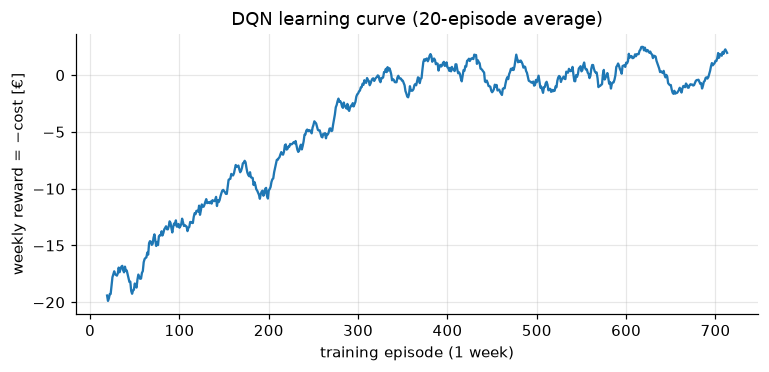

In [8]:
dev = torch.device("cpu")
qnet = nn.Sequential(nn.Linear(9, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, NA)).to(dev)
target = nn.Sequential(nn.Linear(9, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, NA)).to(dev)
target.load_state_dict(qnet.state_dict())
opt = torch.optim.Adam(qnet.parameters(), lr=5e-4)
mu, sd = X_exp.mean(0), X_exp.std(0) + 1e-6                     # feature scaling (statistics only, no expert labels)
norm = lambda x: torch.tensor((np.asarray(x) - mu) / sd, dtype=torch.float32, device=dev)

N_STEPS, BUF = 120_000, 50_000
buf_s, buf_a, buf_r, buf_s2, buf_d = (np.zeros((BUF, 9), np.float32), np.zeros(BUF, int), np.zeros(BUF, np.float32),
                                      np.zeros((BUF, 9), np.float32), np.zeros(BUF, np.float32))
env = HomeBatteryEnv(*TRAIN, seed=1); s, _ = env.reset(); ep_ret, returns, shield_count = 0.0, [], 0
t0 = time.perf_counter()
for step in range(N_STEPS):
    eps = max(0.05, 1 - step / (0.5 * N_STEPS))
    if rng.random() < eps:
        a = rng.integers(NA)
    else:
        with torch.no_grad(): a = int(qnet(norm(s[None, :])).argmax())
    s2, r, done, _, info = env.step(a); shield_count += info["shielded"]
    i = step % BUF; buf_s[i], buf_a[i], buf_r[i], buf_s2[i], buf_d[i] = s, a, r, s2, done
    s, ep_ret = s2, ep_ret + r
    if done:
        returns.append(ep_ret); s, _ = env.reset(); ep_ret = 0.0
    if step >= 2000:
        b = rng.integers(0, min(step + 1, BUF), 256)
        with torch.no_grad():
            y_t = torch.tensor(buf_r[b]) + 0.99 * (1 - torch.tensor(buf_d[b])) * target(norm(buf_s2[b])).max(1).values
        q = qnet(norm(buf_s[b])).gather(1, torch.tensor(buf_a[b])[:, None])[:, 0]
        loss = nn.functional.smooth_l1_loss(q, y_t)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 1000 == 0: target.load_state_dict(qnet.state_dict())
print(f"DQN: {N_STEPS} steps in {time.perf_counter() - t0:.0f} s | shield interventions during training: {shield_count} "
      f"({shield_count / N_STEPS:.0%} of actions)")

def dqn_policy(t, soc):
    with torch.no_grad(): return action_power(int(qnet(norm(features(t, soc)[None, :])).argmax()), t)
results["deep Q-network (DQN)"] = rollout(dqn_policy, *TEST, record=True)

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(pd.Series(returns).rolling(20).mean()); ax.set(xlabel="training episode (1 week)", ylabel="weekly reward = −cost [€]",
                                                      title="DQN learning curve (20-episode average)"); plt.show()

## 5. Results on the test month (September 2019)

,September bill [€],saving vs no battery [€],share of expert's saving,shield interventions
no battery,24.48,0.00,0%,0
rule-based (self-consumption),0.31,24.17,99%,226
expert MPC (continuous power),0.17,24.30,100%,0
expert MPC mapped to the 5 modes,0.19,24.29,100%,122
behaviour cloning,0.56,23.92,98%,132
DAgger (3 iterations),0.78,23.70,98%,120
tabular Q-learning,9.06,15.42,63%,119
deep Q-network (DQN),7.81,16.67,69%,214


decision time: MPC 6.7 ms | DQN 0.12 ms


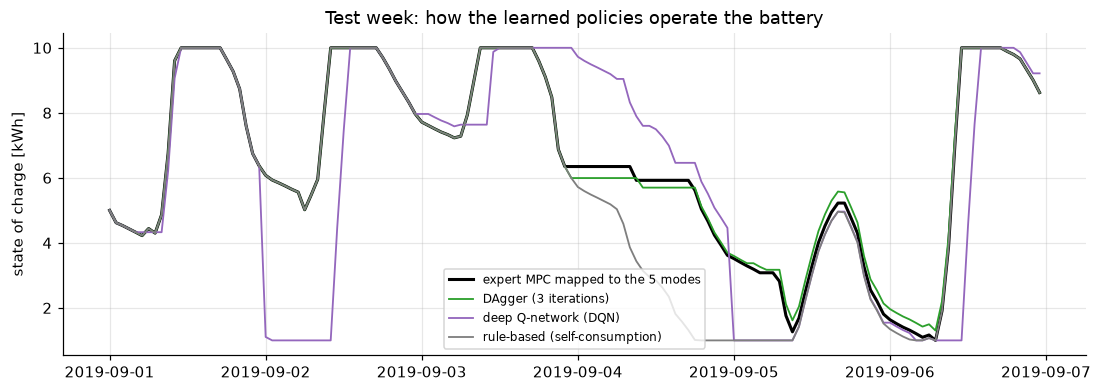

In [9]:
base = results["no battery"][0]
table = pd.DataFrame({k: {"September bill [€]": v[0], "saving vs no battery [€]": base - v[0],
                          "share of expert's saving": (base - v[0]) / (base - results["expert MPC (continuous power)"][0]),
                          "shield interventions": v[1]} for k, v in results.items()}).T
display(table.style.format({"September bill [€]": "{:.2f}", "saving vs no battery [€]": "{:.2f}",
                            "share of expert's saving": "{:.0%}", "shield interventions": "{:.0f}"}))

t1 = time.perf_counter()
for t in range(TEST[0], TEST[0] + 200): dqn_policy(t, 5.0)
print(f"decision time: MPC {expert_ms:.1f} ms | DQN {1000 * (time.perf_counter() - t1) / 200:.2f} ms")

fig, ax = plt.subplots(figsize=(12, 3.8))
for k, c in (("expert MPC mapped to the 5 modes", "k"), ("DAgger (3 iterations)", "tab:green"), ("deep Q-network (DQN)", "tab:purple"),
             ("rule-based (self-consumption)", "tab:grey")):
    tr = results[k][2]
    ax.plot(home.index[days], tr.soc.loc[days.start:days.stop - 1].values, color=c, label=k, lw=2 if c == "k" else 1.2)
ax.set(ylabel="state of charge [kWh]", title="Test week: how the learned policies operate the battery"); ax.legend(fontsize=8); plt.show()

**Reading the results**
* Imitation learning recovers almost all of the expert's saving from a few months of demonstrations.
* Reinforcement learning, after 120 000 simulated hours (≈ 14 years of experience), still captures clearly less than
  the one-line self-consumption rule; the DQN sometimes empties the battery into the grid at 0.08 €/kWh. RL is
  sample-hungry and sensitive to reward scaling, exploration and state design. It earns its place when no expert or
  rule exists and the environment is cheap to simulate, not as a replacement for a working optimiser.
* With operating modes, the shield also does routine clipping (self-consume on a full battery cannot store more), so
  its count is not a measure of danger here; during DQN training it clipped about a quarter of all actions.
* Learned policies decide in ~0.1 ms, about 50× faster than solving the MPC.

## Key takeaways
* A learned policy replaces an online optimisation by one function evaluation: useful for fast control loops and
  embedded devices.
* **Imitation learning** is just supervised learning on expert decisions, but the closed loop feeds the learner its own
  mistakes, so errors *can* compound. DAgger addresses this by labelling the states the learner itself visits.
* **Reinforcement learning** needs no expert, only a reward, at the price of many simulated interactions and careful
  tuning; here it did not reach a simple rule. Always benchmark against rules and optimisers.
* **Safety** must not depend on the learned policy: a shield (projection onto the feasible set) enforces physical limits
  whatever the agent proposes. The same idea scales to grid operation (Grid2Op, notebook 17).